In [1]:
!pip install numpy pandas scipy matplotlib seaborn scikit-learn -q

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 10)
plt.rcParams['font.size'] = 10

print("✓ All libraries loaded successfully!")

✓ All libraries loaded successfully!


In [24]:
df = pd.read_csv('http://people.whitman.edu/~hundledr/courses/M250F03/LynxHare.txt', sep=r'\s+', header=None, names=['Year', 'Hare', 'Lynx'])
print(f"✓ Dataset loaded from Whitman College!")
print(f"   Shape: {df.shape}")
print(f"   Years: {int(df['Year'].min())} - {int(df['Year'].max())}")

✓ Dataset loaded from Whitman College!
   Shape: (91, 3)
   Years: 1845 - 1935


In [5]:
from sklearn.preprocessing import MinMaxScaler

In [25]:
from sklearn.preprocessing import MinMaxScaler

# Create processed dataframe
df_processed = df.copy()

# Log transform (for stability)
df_processed['Log_Hare'] = np.log(df_processed['Hare'].astype(float))
df_processed['Log_Lynx'] = np.log(df_processed['Lynx'].astype(float))

# Normalize to [0, 1]
scaler_hare = MinMaxScaler()
scaler_lynx = MinMaxScaler()

df_processed['Hare_Normalized'] = scaler_hare.fit_transform(df_processed[['Hare']])
df_processed['Lynx_Normalized'] = scaler_lynx.fit_transform(df_processed[['Lynx']])

# Growth rates
df_processed['Hare_Growth'] = df_processed['Hare'].pct_change() * 100
df_processed['Lynx_Growth'] = df_processed['Lynx'].pct_change() * 100

# Scale for ODE (range [1, 100])
hare_scaled = df_processed['Hare_Normalized'].values * 99 + 1
lynx_scaled = df_processed['Lynx_Normalized'].values * 99 + 1
years = df['Year'].values
time_points = years - years[0]

print(f"✓ Data preprocessing complete!")
print(f"   Hare scaled: {hare_scaled.min():.2f} - {hare_scaled.max():.2f}")
print(f"   Lynx scaled: {lynx_scaled.min():.2f} - {lynx_scaled.max():.2f}")
print(f"   Time points: 0 - {time_points.max():.0f} years")

✓ Data preprocessing complete!
   Hare scaled: 1.00 - 100.00
   Lynx scaled: 1.00 - 100.00
   Time points: 0 - 90 years



 Creating EDA visualizations...


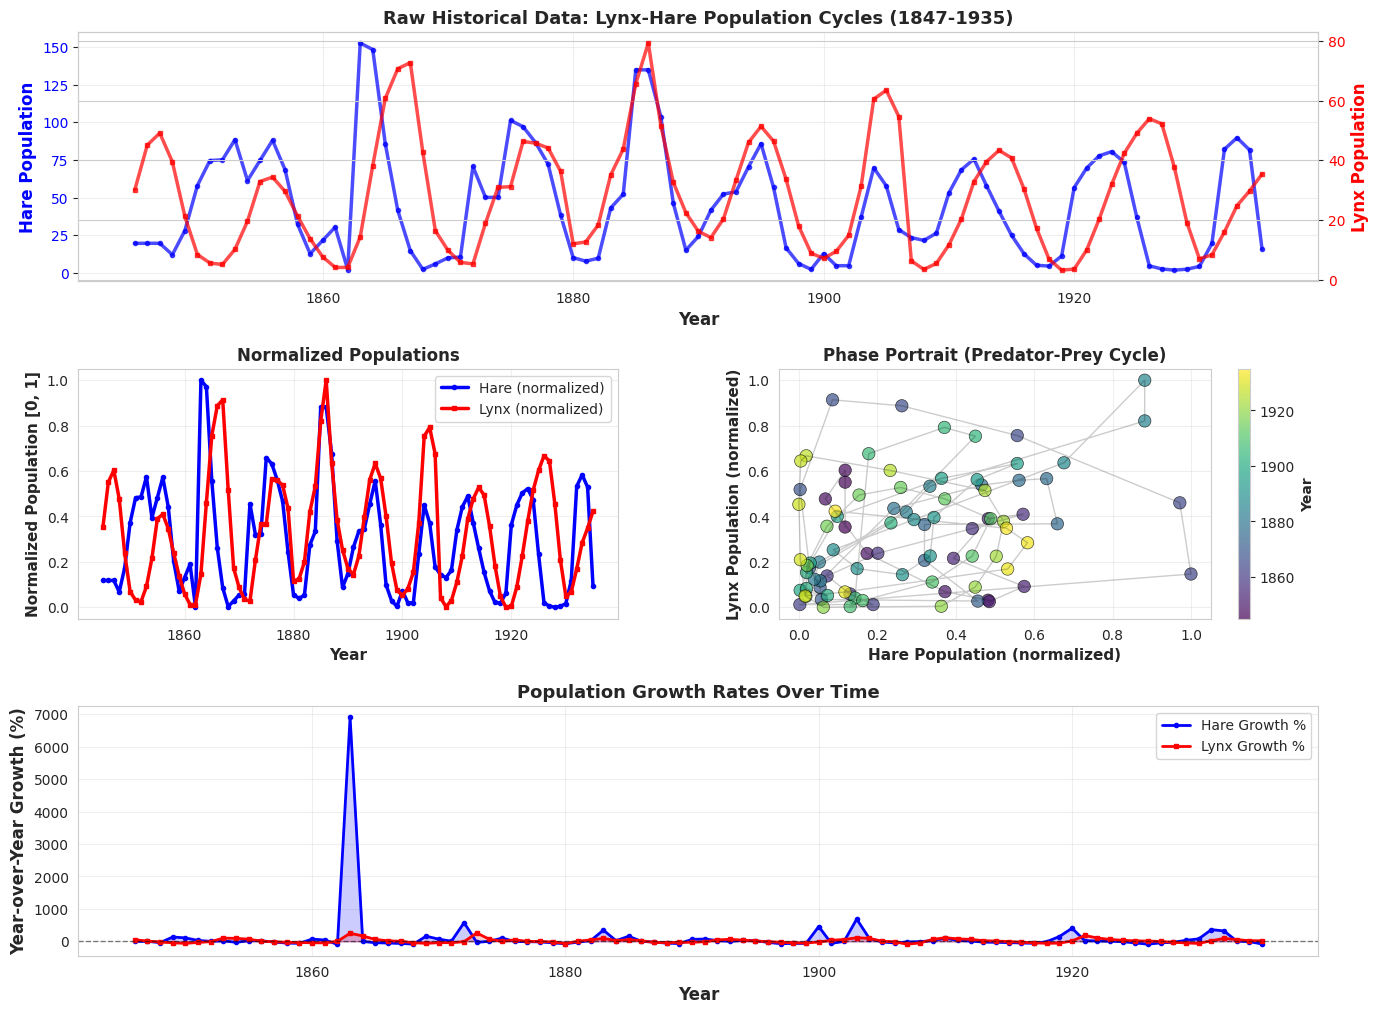

✓ EDA visualization complete! (saved as 01_eda_analysis.png)


In [27]:
print("\n Creating EDA visualizations...")

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.3)

# PLOT 1: Raw Time Series
ax1 = fig.add_subplot(gs[0, :])
ax1_twin = ax1.twinx()

ax1.plot(years, df['Hare'].values, 'b-', linewidth=2.5, label='Hare', marker='o', markersize=3, alpha=0.7)
ax1_twin.plot(years, df['Lynx'].values, 'r-', linewidth=2.5, label='Lynx', marker='s', markersize=3, alpha=0.7)

ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Hare Population', fontsize=12, fontweight='bold', color='b')
ax1_twin.set_ylabel('Lynx Population', fontsize=12, fontweight='bold', color='r')
ax1.set_title('Raw Historical Data: Lynx-Hare Population Cycles (1847-1935)', fontsize=13, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='b')
ax1_twin.tick_params(axis='y', labelcolor='r')
ax1.grid(True, alpha=0.3)

# PLOT 2: Normalized Populations
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(years, df_processed['Hare_Normalized'], 'b-', linewidth=2.5, label='Hare (normalized)', marker='o', markersize=3)
ax2.plot(years, df_processed['Lynx_Normalized'], 'r-', linewidth=2.5, label='Lynx (normalized)', marker='s', markersize=3)
ax2.set_xlabel('Year', fontsize=11, fontweight='bold')
ax2.set_ylabel('Normalized Population [0, 1]', fontsize=11, fontweight='bold')
ax2.set_title('Normalized Populations', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_ylim([-0.05, 1.05])

# PLOT 3: Phase Portrait
ax3 = fig.add_subplot(gs[1, 1])
scatter = ax3.scatter(df_processed['Hare_Normalized'], df_processed['Lynx_Normalized'],
                     c=years, cmap='viridis', s=80, alpha=0.7, edgecolors='black', linewidth=0.5)
ax3.plot(df_processed['Hare_Normalized'], df_processed['Lynx_Normalized'], 'k-', alpha=0.2, linewidth=1)
ax3.set_xlabel('Hare Population (normalized)', fontsize=11, fontweight='bold')
ax3.set_ylabel('Lynx Population (normalized)', fontsize=11, fontweight='bold')
ax3.set_title('Phase Portrait (Predator-Prey Cycle)', fontsize=12, fontweight='bold')
cbar = plt.colorbar(scatter, ax=ax3)
cbar.set_label('Year', fontsize=10, fontweight='bold')
ax3.grid(True, alpha=0.3)

# PLOT 4: Growth Rates
ax4 = fig.add_subplot(gs[2, :])
ax4.plot(years[1:], df_processed['Hare_Growth'].values[1:], 'b-', linewidth=2, label='Hare Growth %', marker='o', markersize=3)
ax4.plot(years[1:], df_processed['Lynx_Growth'].values[1:], 'r-', linewidth=2, label='Lynx Growth %', marker='s', markersize=3)
ax4.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
ax4.fill_between(years[1:], 0, df_processed['Hare_Growth'].values[1:], alpha=0.2, color='blue')
ax4.fill_between(years[1:], 0, df_processed['Lynx_Growth'].values[1:], alpha=0.2, color='red')
ax4.set_xlabel('Year', fontsize=12, fontweight='bold')
ax4.set_ylabel('Year-over-Year Growth (%)', fontsize=12, fontweight='bold')
ax4.set_title('Population Growth Rates Over Time', fontsize=13, fontweight='bold')
ax4.legend(loc='upper right', fontsize=10)
ax4.grid(True, alpha=0.3)

plt.savefig('01_eda_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ EDA visualization complete! (saved as 01_eda_analysis.png)")

In [44]:
def lotka_volterra(state, t, alpha, beta, gamma, delta):
    """Lotka-Volterra predator-prey ODE system"""
    x, y = state
    dx_dt = alpha * x - beta * x * y
    dy_dt = -gamma * y + delta * x * y
    return [dx_dt, dy_dt]

def fitness_function(params):
    """RMSE error between model and data"""
    alpha, beta, gamma, delta = params

    # Constraints for biological realism
    if alpha < 0.3 or alpha > 1.0:
        return 1e6
    if beta < 0.02 or beta > 0.15:
        return 1e6
    if gamma < 0.4 or gamma > 1.5:
        return 1e6
    if delta < 0.005 or delta > 0.05:
        return 1e6


    try:
        initial_state = [hare_scaled[0], lynx_scaled[0]]
        solution = odeint(lotka_volterra, initial_state, time_points, args=(alpha, beta, gamma, delta))
        hare_pred = solution[:, 0]
        lynx_pred = solution[:, 1]

        hare_rmse = np.sqrt(np.mean((hare_scaled - hare_pred) ** 2))
        lynx_rmse = np.sqrt(np.mean((lynx_scaled - lynx_pred) ** 2))
        total_error = 0.5 * hare_rmse + 0.5 * lynx_rmse
        return total_error
    except:
        return 1e6

def compute_r_squared(params):
    """Compute R² for model"""
    alpha, beta, gamma, delta = params
    try:
        initial_state = [hare_scaled[0], lynx_scaled[0]]
        solution = odeint(lotka_volterra, initial_state, time_points, args=(alpha, beta, gamma, delta))
        hare_pred = solution[:, 0]
        lynx_pred = solution[:, 1]

        hare_ss_res = np.sum((hare_scaled - hare_pred) ** 2)
        hare_ss_tot = np.sum((hare_scaled - np.mean(hare_scaled)) ** 2)
        hare_r2 = 1 - (hare_ss_res / hare_ss_tot) if hare_ss_tot > 0 else 0

        lynx_ss_res = np.sum((lynx_scaled - lynx_pred) ** 2)
        lynx_ss_tot = np.sum((lynx_scaled - np.mean(lynx_scaled)) ** 2)
        lynx_r2 = 1 - (lynx_ss_res / lynx_ss_tot) if lynx_ss_tot > 0 else 0

        return hare_r2, lynx_r2
    except:
        return -1, -1

print("✓ ODE system and fitness function ready!")
def compute_mape(actual, predicted):
    """Compute Mean Absolute Percentage Error (MAPE)"""
    mask = actual != 0
    mape = 100.0 * np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask]))
    return mape

def compute_mape_values(params):
    """Calculate MAPE for both hare and lynx"""
    alpha, beta, gamma, delta = params
    try:
        initial_state = [hare_scaled[0], lynx_scaled[0]]
        solution = odeint(lotka_volterra, initial_state, time_points,
                         args=(alpha, beta, gamma, delta))
        hare_pred = solution[:, 0]
        lynx_pred = solution[:, 1]
        hare_mape = compute_mape(hare_scaled, hare_pred)
        lynx_mape = compute_mape(lynx_scaled, lynx_pred)
        return hare_mape, lynx_mape
    except:
        return 999.0, 999.0


✓ ODE system and fitness function ready!


In [49]:
class GeneticAlgorithm:
    """Genetic Algorithm for parameter estimation"""

    def __init__(self, pop_size=100, generations=150, mutation_rate=0.15, crossover_rate=0.85, elitism_rate=0.10):
        self.pop_size = pop_size if pop_size % 2 == 0 else pop_size + 1
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.crossover_rate = crossover_rate
        self.elitism_rate = elitism_rate
        self.n_elites = max(1, int(elitism_rate * pop_size))

        self.param_bounds = {
            'alpha': (0.4, 1.2),
            'beta': (0.03, 0.12),
            'gamma': (0.5, 2.0),
            'delta': (0.005, 0.05)
        }

        self.history = {'best_fitness': [], 'mean_fitness': [], 'best_params': []}

    def initialize_population(self):
        population = []
        for _ in range(self.pop_size):
            individual = [
                np.random.uniform(self.param_bounds['alpha'][0], self.param_bounds['alpha'][1]),
                np.random.uniform(self.param_bounds['beta'][0], self.param_bounds['beta'][1]),
                np.random.uniform(self.param_bounds['gamma'][0], self.param_bounds['gamma'][1]),
                np.random.uniform(self.param_bounds['delta'][0], self.param_bounds['delta'][1])
            ]
            population.append(individual)
        return np.array(population)

    def evaluate_fitness(self, population):
        fitness = np.array([fitness_function(ind) for ind in population])
        return fitness

    def tournament_selection(self, population, fitness, tournament_size=5):
        selected = []
        for _ in range(len(population)):
            tournament_idx = np.random.choice(len(population), tournament_size, replace=False)
            winner_idx = tournament_idx[np.argmin(fitness[tournament_idx])]
            selected.append(population[winner_idx].copy())
        return np.array(selected)

    def crossover(self, parent1, parent2):
        if np.random.random() < self.crossover_rate:
            mask = np.random.random(len(parent1)) < 0.5
            child1 = np.where(mask, parent1, parent2)
            child2 = np.where(mask, parent2, parent1)
            return child1, child2
        else:
            return parent1.copy(), parent2.copy()

    def mutate(self, individual):
        mutated = individual.copy()
        for i in range(len(mutated)):
            if np.random.random() < self.mutation_rate:
                param_name = list(self.param_bounds.keys())[i]
                bounds = self.param_bounds[param_name]
                param_range = bounds[1] - bounds[0]
                mutation = np.random.normal(0, param_range * 0.1)
                mutated[i] = mutated[i] + mutation
                mutated[i] = np.clip(mutated[i], bounds[0], bounds[1])
        return mutated

    def evolve(self, verbose=True):
        print("\n🧬 Starting Genetic Algorithm evolution...")
        print(f"   Population: {self.pop_size}, Generations: {self.generations}\n")

        population = self.initialize_population()

        for gen in range(self.generations):
            fitness = self.evaluate_fitness(population)
            best_idx = np.argmin(fitness)
            best_fitness = fitness[best_idx]
            mean_fitness = np.mean(fitness)

            self.history['best_fitness'].append(best_fitness)
            self.history['mean_fitness'].append(mean_fitness)
            self.history['best_params'].append(population[best_idx].copy())

            if verbose and (gen % 30 == 0 or gen == self.generations - 1):
                print(f"   Gen {gen:3d}/{self.generations}: Best={best_fitness:8.4f}, Mean={mean_fitness:8.4f}")

            elite_idx = np.argsort(fitness)[:self.n_elites]
            elites = population[elite_idx].copy()
            selected = self.tournament_selection(population, fitness)

            offspring = []
            for i in range(0, len(selected), 2):
                if i + 1 < len(selected):
                    child1, child2 = self.crossover(selected[i], selected[i+1])
                    child1 = self.mutate(child1)
                    child2 = self.mutate(child2)
                    offspring.extend([child1, child2])

            offspring_array = np.array(offspring)
            new_pop_size = self.pop_size - self.n_elites
            new_population = list(elites) + list(offspring_array[:new_pop_size])
            population = np.array(new_population)

        final_fitness = self.evaluate_fitness(population)
        best_idx = np.argmin(final_fitness)
        best_params = population[best_idx]
        best_error = final_fitness[best_idx]

        print("\n✓ GA evolution complete!")
        return best_params, best_error

print("✓ Genetic Algorithm class ready!")

✓ Genetic Algorithm class ready!


In [50]:
ga = GeneticAlgorithm(pop_size=150, generations=200, mutation_rate=0.15, crossover_rate=0.85, elitism_rate=0.10)
best_params_ga, best_error_ga = ga.evolve(verbose=True)

print(f"\n✓✓✓ BEST PARAMETERS FOUND: ✓✓✓")
print(f"   α (Prey growth rate):        {best_params_ga[0]:.6f}")
print(f"   β (Predation coefficient):   {best_params_ga[1]:.6f}")
print(f"   γ (Predator mortality):      {best_params_ga[2]:.6f}")
print(f"   δ (Predator reproduction):   {best_params_ga[3]:.6f}")
print(f"\n   RMSE Error: {best_error_ga:.6f}")

hare_r2, lynx_r2 = compute_r_squared(best_params_ga)
print(f"   R² (Hare): {hare_r2:.4f}")
print(f"   R² (Lynx): {lynx_r2:.4f}")
# Calculate MAPE
hare_mape, lynx_mape = compute_mape_values(best_params_ga)
print(f"Mean Absolute Percentage Error (Hare):   {hare_mape:.2f} %")
print(f"Mean Absolute Percentage Error (Lynx):   {lynx_mape:.2f} %")


🧬 Starting Genetic Algorithm evolution...
   Population: 150, Generations: 200

   Gen   0/200: Best= 26.4980, Mean=520025.2140
   Gen  30/200: Best= 23.3541, Mean= 24.5894
   Gen  60/200: Best= 23.2214, Mean= 24.4667
   Gen  90/200: Best= 23.2202, Mean= 24.5755
   Gen 120/200: Best= 23.2194, Mean= 24.2809
   Gen 150/200: Best= 23.1657, Mean= 24.4584
   Gen 180/200: Best= 23.1589, Mean= 24.2181
   Gen 199/200: Best= 23.1586, Mean= 24.3991

✓ GA evolution complete!

✓✓✓ BEST PARAMETERS FOUND: ✓✓✓
   α (Prey growth rate):        0.798519
   β (Predation coefficient):   0.030000
   γ (Predator mortality):      0.500000
   δ (Predator reproduction):   0.021823

   RMSE Error: 23.158635
   R² (Hare): -0.0905
   R² (Lynx): 0.2209
Mean Absolute Percentage Error (Hare):   185.98 %
Mean Absolute Percentage Error (Lynx):   147.85 %



📊 Creating results visualization...


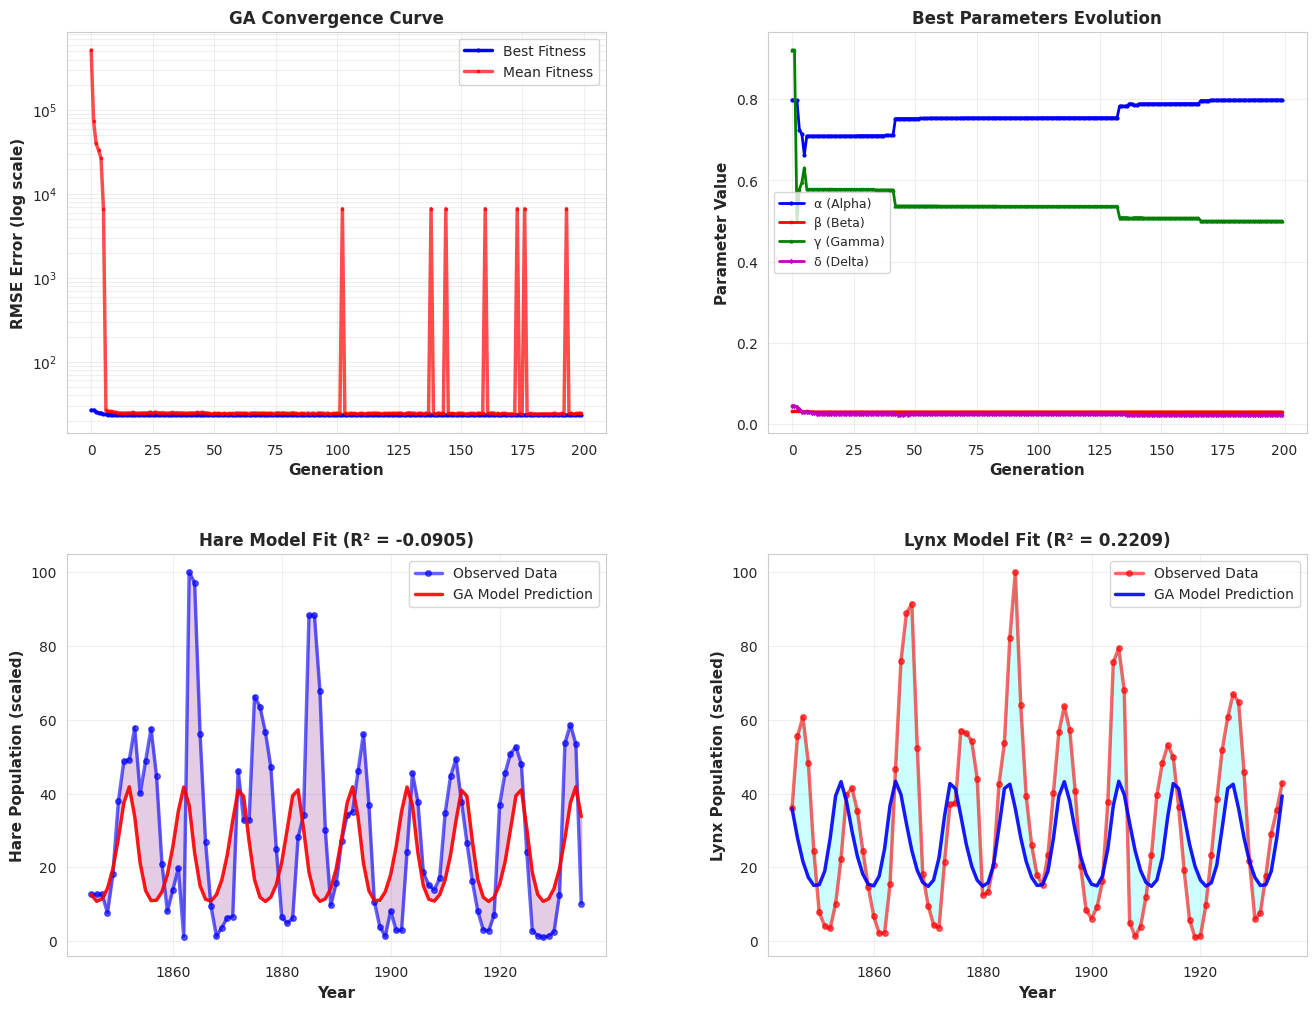

✓ Results visualization complete! (saved as 02_ga_results.png)


In [52]:
print("\n📊 Creating results visualization...")

# Generate predictions with best parameters
initial_state = [hare_scaled[0], lynx_scaled[0]]
solution_ga = odeint(lotka_volterra, initial_state, time_points, args=tuple(best_params_ga))
hare_pred_ga = solution_ga[:, 0]
lynx_pred_ga = solution_ga[:, 1]

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3)

# Convergence
ax1 = fig.add_subplot(gs[0, 0])
ax1.semilogy(ga.history['best_fitness'], 'b-', linewidth=2.5, label='Best Fitness', marker='o', markersize=2)
ax1.semilogy(ga.history['mean_fitness'], 'r-', linewidth=2.5, label='Mean Fitness', alpha=0.7, marker='s', markersize=2)
ax1.set_xlabel('Generation', fontsize=11, fontweight='bold')
ax1.set_ylabel('RMSE Error (log scale)', fontsize=11, fontweight='bold')
ax1.set_title('GA Convergence Curve', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, which='both')

# Parameters evolution
ax2 = fig.add_subplot(gs[0, 1])
best_params_history = np.array(ga.history['best_params'])
ax2.plot(best_params_history[:, 0], 'b-', label='α (Alpha)', linewidth=2, marker='o', markersize=2)
ax2.plot(best_params_history[:, 1], 'r-', label='β (Beta)', linewidth=2, marker='s', markersize=2)
ax2.plot(best_params_history[:, 2], 'g-', label='γ (Gamma)', linewidth=2, marker='^', markersize=2)
ax2.plot(best_params_history[:, 3], 'm-', label='δ (Delta)', linewidth=2, marker='d', markersize=2)
ax2.set_xlabel('Generation', fontsize=11, fontweight='bold')
ax2.set_ylabel('Parameter Value', fontsize=11, fontweight='bold')
ax2.set_title('Best Parameters Evolution', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

# Hare fit
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(years, hare_scaled, 'bo-', label='Observed Data', linewidth=2.5, markersize=4, alpha=0.6)
ax3.plot(years, hare_pred_ga, 'r-', label='GA Model Prediction', linewidth=2.5, alpha=0.9)
ax3.fill_between(years, hare_scaled, hare_pred_ga, alpha=0.2, color='purple')
ax3.set_xlabel('Year', fontsize=11, fontweight='bold')
ax3.set_ylabel('Hare Population (scaled)', fontsize=11, fontweight='bold')
ax3.set_title(f'Hare Model Fit (R² = {hare_r2:.4f})', fontsize=12, fontweight='bold')
ax3.legend(fontsize=10)
ax3.grid(True, alpha=0.3)

# Lynx fit
ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(years, lynx_scaled, 'ro-', label='Observed Data', linewidth=2.5, markersize=4, alpha=0.6)
ax4.plot(years, lynx_pred_ga, 'b-', label='GA Model Prediction', linewidth=2.5, alpha=0.9)
ax4.fill_between(years, lynx_scaled, lynx_pred_ga, alpha=0.2, color='cyan')
ax4.set_xlabel('Year', fontsize=11, fontweight='bold')
ax4.set_ylabel('Lynx Population (scaled)', fontsize=11, fontweight='bold')
ax4.set_title(f'Lynx Model Fit (R² = {lynx_r2:.4f})', fontsize=12, fontweight='bold')
ax4.legend(fontsize=10)
ax4.grid(True, alpha=0.3)

plt.savefig('02_ga_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Results visualization complete! (saved as 02_ga_results.png)")



📈 Creating residual analysis...


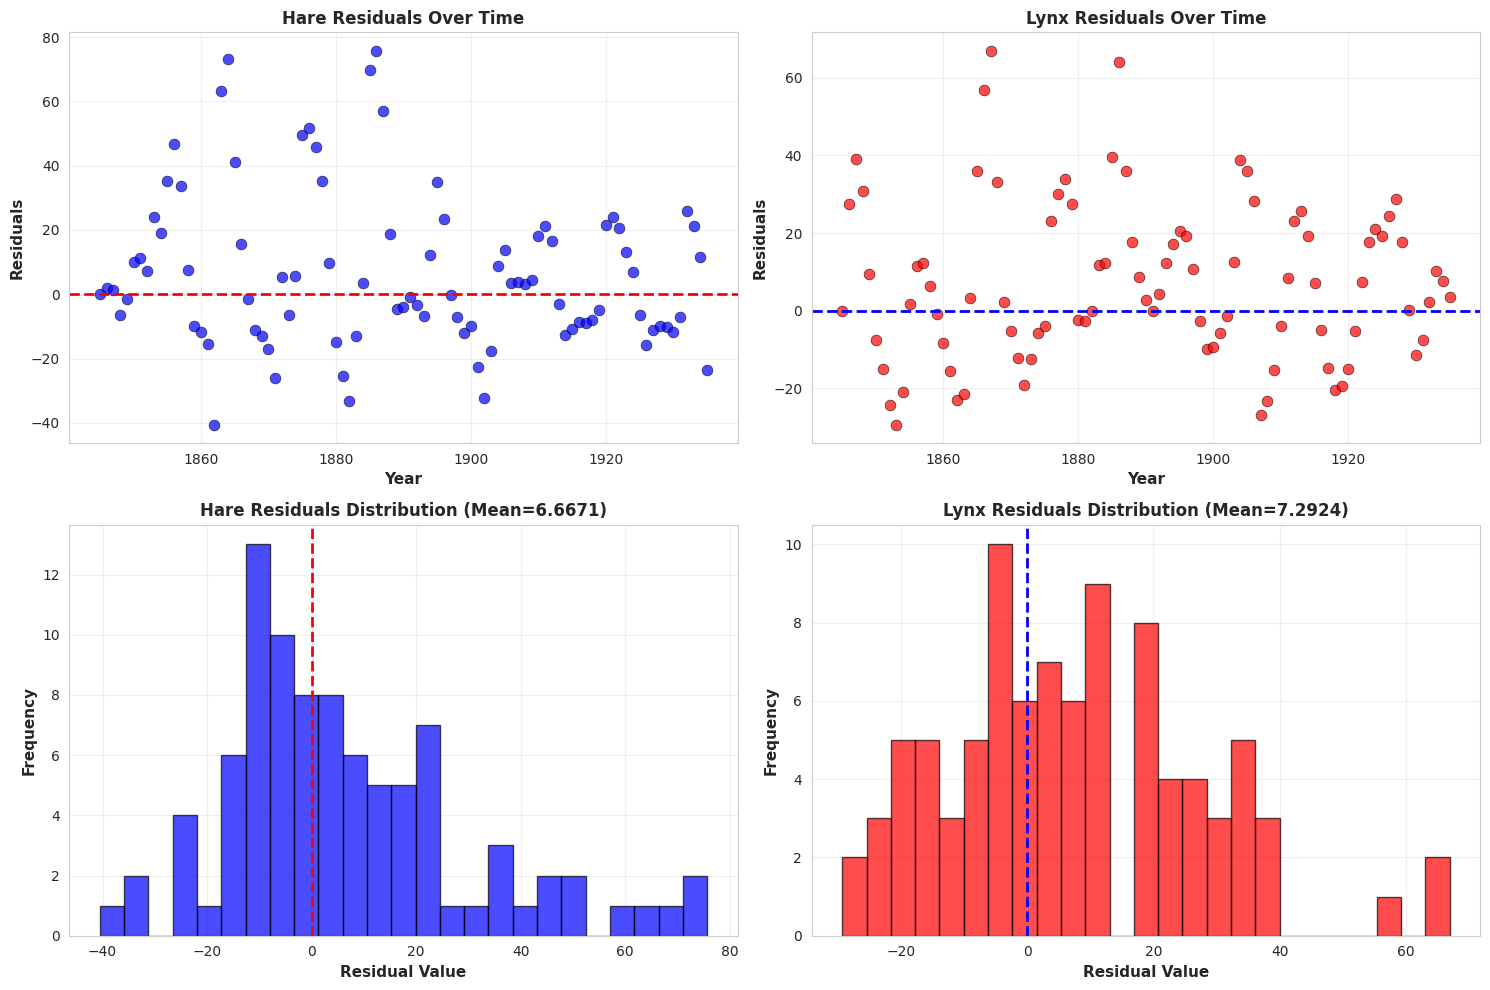

✓ Residual analysis complete! (saved as 03_residual_analysis.png)


In [53]:
print("\n📈 Creating residual analysis...")

hare_residuals = hare_scaled - hare_pred_ga
lynx_residuals = lynx_scaled - lynx_pred_ga

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Hare residuals vs time
axes[0, 0].scatter(years, hare_residuals, alpha=0.7, s=60, color='blue', edgecolors='black', linewidth=0.5)
axes[0, 0].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Year', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Residuals', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Hare Residuals Over Time', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Lynx residuals vs time
axes[0, 1].scatter(years, lynx_residuals, alpha=0.7, s=60, color='red', edgecolors='black', linewidth=0.5)
axes[0, 1].axhline(y=0, color='b', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Year', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Residuals', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Lynx Residuals Over Time', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# Hare residuals histogram
axes[1, 0].hist(hare_residuals, bins=25, color='blue', alpha=0.7, edgecolor='black')
axes[1, 0].axvline(x=0, color='r', linestyle='--', linewidth=2)
axes[1, 0].set_xlabel('Residual Value', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[1, 0].set_title(f'Hare Residuals Distribution (Mean={np.mean(hare_residuals):.4f})', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Lynx residuals histogram
axes[1, 1].hist(lynx_residuals, bins=25, color='red', alpha=0.7, edgecolor='black')
axes[1, 1].axvline(x=0, color='b', linestyle='--', linewidth=2)
axes[1, 1].set_xlabel('Residual Value', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[1, 1].set_title(f'Lynx Residuals Distribution (Mean={np.mean(lynx_residuals):.4f})', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('03_residual_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Residual analysis complete! (saved as 03_residual_analysis.png)")


🔄 Creating phase portrait...


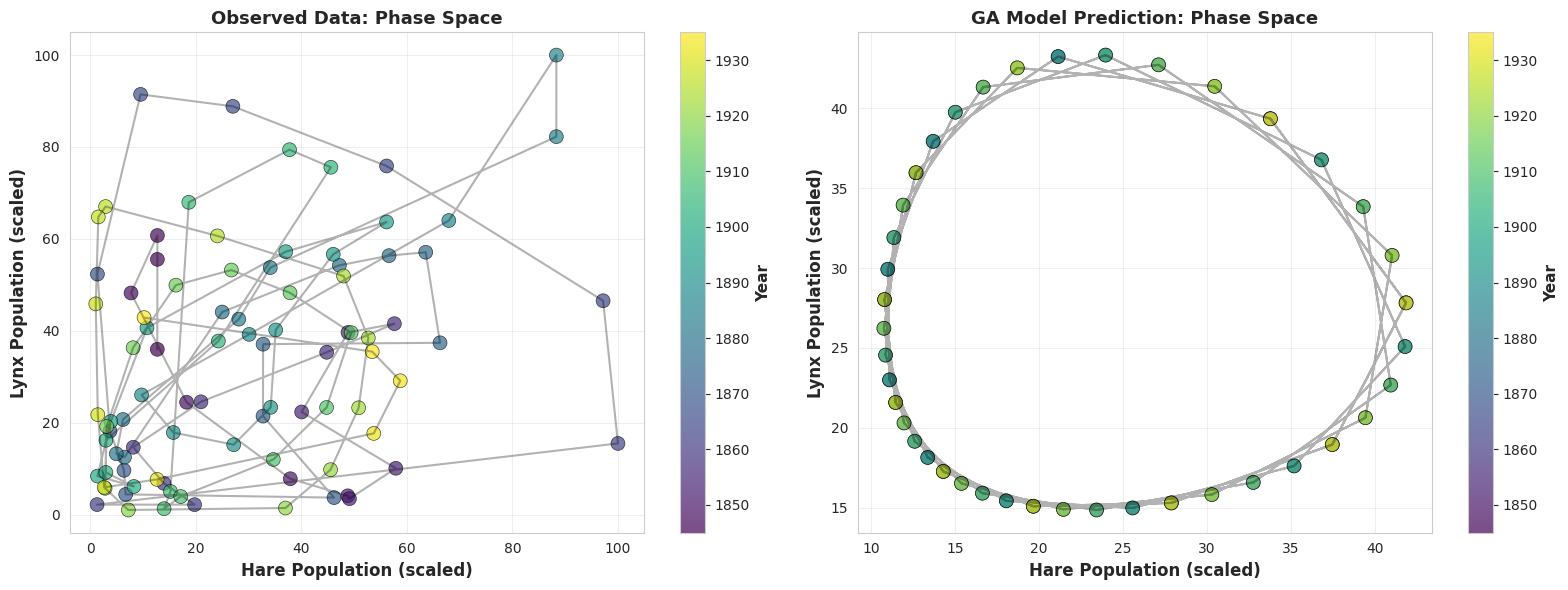

✓ Phase portrait complete! (saved as 04_phase_portrait.png)


In [54]:
print("\n🔄 Creating phase portrait...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Observed phase portrait
scatter1 = axes[0].scatter(hare_scaled, lynx_scaled, c=years, cmap='viridis', s=100, alpha=0.7, edgecolors='black', linewidth=0.5)
axes[0].plot(hare_scaled, lynx_scaled, 'k-', alpha=0.3, linewidth=1.5)
axes[0].set_xlabel('Hare Population (scaled)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Lynx Population (scaled)', fontsize=12, fontweight='bold')
axes[0].set_title('Observed Data: Phase Space', fontsize=13, fontweight='bold')
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Year', fontsize=11, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Predicted phase portrait
scatter2 = axes[1].scatter(hare_pred_ga, lynx_pred_ga, c=years, cmap='viridis', s=100, alpha=0.7, edgecolors='black', linewidth=0.5)
axes[1].plot(hare_pred_ga, lynx_pred_ga, 'k-', alpha=0.3, linewidth=1.5)
axes[1].set_xlabel('Hare Population (scaled)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Lynx Population (scaled)', fontsize=12, fontweight='bold')
axes[1].set_title('GA Model Prediction: Phase Space', fontsize=13, fontweight='bold')
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Year', fontsize=11, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('04_phase_portrait.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Phase portrait complete! (saved as 04_phase_portrait.png)")